<img src="conative_systems_logo.svg" align="right" width="125" style="float: right; margin-left: 20px; margin-bottom: 15px;" alt="Conative Systems Logo" />

# Active Conative Inference (ACI): The Planar Inverted Pendulum
### A Didactic First-Principles Walkthrough of Perception, Action, Vitality, and Online Learning in a Planar 2D System
**Author:** Thomas Riebl  
**Organization:** Conative Systems S.à r.l.  
**Theoretical Basis:** Active Conative Inference (ACI), Free Energy Principle (FEP), Integrated Information Theory ($\Phi$ / IIT 4.0), Spinozan Conatus, Patent 01 & 11

---

## 1. Physical Intuition: The Palm-Balancing Paradox & Planar Architecture

Before formalizing any mathematics or probability matrices, let us anchor the system in everyday physical intuition.

Imagine balancing a long broomstick vertically on the open palm of your hand:
* When the top of the stick begins tilting to the **right**, what must your hand do?
* Human instinct might mistakenly tempt you to pull your hand away to the left. But classical Newton-Euler physics dictates the exact opposite: your hand must dart quickly to the **RIGHT**, positioning the base pivot directly underneath the falling Center of Mass (CoM).
* The resulting inertial reaction torque swings the rod back toward vertical balance ($0^\circ$).

In this planar 2D system, motion is strictly constrained to a single vertical plane: the base cart moves along the horizontal $x$-axis, and the pendulum tilts strictly **Left** ($l$) or **Right** ($r$).

---

### 1.1 Physical Kinematic Diagram (Step 1: The Intuitive Cart-Pole)

The following vector graphic illustrates the fundamental physical setup before introducing discrete probability bins or matrix mathematics:

![1. Physical System: The Planar Inverted Pendulum](inverted_pendulum_step1_physics.svg)

#### Visual Elements of the Physical Stage:
1. **The Mobile Base Cart (Mass $M$):** Constrained to move strictly along the horizontal $x$-axis on the linear floor track (Left ↔ Right). There are no out-of-plane forward/rear degrees of freedom.
2. **The Rigid Balancing Rod (Length $L$, Mass $m$):** Attached to the cart at a low-friction pivot pin $(x, 0)$, tilting freely at continuous angle $\theta$.
3. **Vertical Equilibrium ($\theta = 0^\circ$, Green Dashed Line):** The unstable mechanical equilibrium stance where the Center of Mass (CoM) is positioned vertically above the pivot.
4. **The Palm-Balancing Paradox:** If the rod tips to the right ($+\theta$), the cart must accelerate rapidly to the **RIGHT** to position the pivot underneath the falling mass and swing the rod back upright.

---

## 2. The Agent's Mind: Bayes' Theorem & Foundational Probability

Now that the physical pendulum and its balance mechanics are visually and intuitively grounded, we turn to the controller: **How does the agent infer what is happening in the real world?**

In classical textbook control theory, controllers often assume instantaneous, perfect knowledge of the true angle $\theta$. In reality, physical sensors are noisy, encoders have quantization jitter, and air currents disturb the rod. The agent never has direct, omniscient access to the outside world; it must continually infer what is happening through its sensory boundary (the **Markov blanket**).

### Core Notational Elements: $s, o, a, P$

* **$s$ (Hidden State):** The true, unobservable physical condition of the external world (e.g., the actual tilt angle of the rod $\theta \in \mathcal{S}$). The agent can never touch $s$ directly.
* **$o$ (Observation):** The noisy sensory measurement registered by the agent's sensors at the boundary (e.g., optical encoder reading or proprioceptive sensor $o \in \mathcal{O}$).
* **$a$ (Action):** The physical intervention or motor command emitted by the agent into the environment (e.g., base cart acceleration $a \in \mathcal{A}$).
* **$P$ (Probability Distribution):** The mathematical assignment of likelihood, belief, or transition frequency across states and observations ($P \in [0, 1]$).
* **The Conditioning Bar ($\mid$):** Read as **"given"**. For instance, $P(s \mid o)$ is read as *"the probability of hidden state $s$ **given** sensory observation $o$"*.

---

### Bayes' Theorem in Perception

Bayes' Theorem provides the exact mathematical law for updating an internal hypothesis in light of incoming noisy sensory evidence:

$$P(s \mid o) = \frac{P(o \mid s) \cdot P(s)}{P(o)} = \frac{P(o \mid s) \cdot P(s)}{\sum_{s'} P(o \mid s') \cdot P(s')}$$

#### The Four Core Components:
1. **Prior Belief $P(s)$:**  
   What the agent believes about the world **before** looking at the new sensory reading. In our pendulum, this is either the initial upright stance vector $\mathbf{D} = P(s_0)$ or the forward prediction generated by the transition model:
   $$s_{\text{pred}} = \mathbf{B}(a_{t-1}) \cdot s_{t-1}$$
2. **Likelihood $P(o \mid s)$ (Matrix $\mathbf{A}$):**  
   The generative mapping: *"If the rod were genuinely in physical state $s$, how probable is it that our sensor reports observation $o$?"*  
   This captures the fidelity and precision of the sensory apparatus, including sensor noise $\varepsilon$ and diagonal precision $\gamma_s$.
3. **Posterior Belief $P(s \mid o)$ (Read: "$s$ given $o$"):**  
   The updated, optimal belief about the hidden state $s$ **after** assimilating observation $o$. Perception in Active Inference is nothing other than minimizing the discrepancy (Variational Free Energy $F$) between this Bayesian posterior and the agent's internal recognition density $q(s)$.
4. **Marginal Evidence $P(o)$:**  
   The total probability of observing $o$ averaged over all possible world states. Its logarithm $\ln P(o)$ forms the homeostatic phenotype preference vector $\mathbf{C}$.

---

## 3. Mapping the Physical World to Active Inference: Four Intuitive Objects

By constraining the system to a single plane (Left/Right), our generative model simplifies down to just **5 states** and **2 actions**:

1. **Where do we need to be? $\to \mathbf{C}$ (Phenotypic Preference):**  
   The biological/autopoietic desire of the system. Upright equilibrium ($s_0$) is homeostatic bliss ($C_0 = 0.0$). Mild tilts carry small surprise penalty ($C = -1.5$). Catastrophic tipping is existential disaster ($C = -8.0$).
2. **Where do we believe we start? $\to \mathbf{D}$ (Prior Belief):**  
   The initial hypothesis before taking the first measurement ($92\%$ certainty of standing upright at $t = 0$).
3. **How clearly do we see the rod? $\to \mathbf{A}$ (Likelihood Matrix):**  
   A transparent $5 \times 5$ matrix capturing sensor fidelity ($92\%$ diagonal precision, with $4\%$ blur into directly adjacent tilt states).
4. **What happens when we move the cart? $\to \mathbf{B}(a)$ (Causal Transition Tensors):**  
   Two intuitive $5 \times 5$ matrices ($\mathbf{B}(l)$ and $\mathbf{B}(r)$) encoding the laws of Newton-Euler physics: accelerating right ($a = r$) when tilted right ($r_1$) restores vertical balance ($0$) with $88\%$ probability.

---

## 4. Formal 5-State Mathematical Specification

### Discrete State Space ($|\mathcal{S}| = 5$) and Action Space ($|\mathcal{A}| = 2$)

* **States:** $\mathcal{S} = \{0, l_1, l_2, r_1, r_2\}$
  * $s_0 = 0$: Upright Stance (Balanced / Homeostatic Attractor)
  * $s_1 = l_1$: Slight Tilt Left ($\theta \approx -12^\circ$)
  * $s_2 = l_2$: Severe Fall Left ($\theta \approx -26^\circ$)
  * $s_3 = r_1$: Slight Tilt Right ($\theta \approx +12^\circ$)
  * $s_4 = r_2$: Severe Fall Right ($\theta \approx +26^\circ$)
* **Actions:** $\mathcal{A} = \{l, r\}$
  * $a = 0$ ($l$): Accelerate Base LEFT ⬅
  * $a = 1$ ($r$): Accelerate Base RIGHT ➔

---

### Prior Belief Vector $\mathbf{D}$ (Initial State)

$$\mathbf{D} = P(s_0) = \begin{pmatrix} 0.92 \\ 0.04 \\ 0.00 \\ 0.04 \\ 0.00 \end{pmatrix} \begin{matrix} (0) \\ (l_1) \\ (l_2) \\ (r_1) \\ (r_2) \end{matrix}$$

* $P(s = 0) = 0.92$: High initial certainty for the upright stance.
* Small residual probability mass ($0.04$) on level-1 deviations ensures sensorimotor flexibility and avoids numerical zero-probability traps.
* Zero initial probability ($0.00$) for catastrophic tipping (level 2).

---

### Homeostatic Preference Vector $\mathbf{C}$ (Conative Attractor)

$$\mathbf{C} = \ln P(o) = \begin{pmatrix} 0.0 \\ -1.5 \\ -8.0 \\ -1.5 \\ -8.0 \end{pmatrix} \begin{matrix} (o_0) \\ (o_{l1}) \\ (o_{l2}) \\ (o_{r1}) \\ (o_{r2}) \end{matrix}$$

* $\mathbf{C}_0 = 0.0$: Maximum preference (zero surprise / minimum Free Energy in stable equilibrium).
* $\mathbf{C}_{\text{Level 1}} = -1.5$: Mild aversion against minor tilts (generates corrective action motivation).
* $\mathbf{C}_{\text{Level 2}} = -8.0$: Catastrophically negative preference (tipping boundary / existential hazard to the physical system).

---

### Likelihood Matrix $\mathbf{A}$ (Sensor Precision)

The matrix $\mathbf{A} \in \mathbb{R}^{5 \times 5}$ maps the hidden physical world state $s$ to sensory observations $o$ across the Markov blanket: $P(o \mid s)$.

For optical or proprioceptive sensing with precision $\gamma_s = 0.92$ and neighboring perceptual noise $\varepsilon = 0.04$:

$$\mathbf{A} = P(o \mid s) = \begin{pmatrix}
0.92 & 0.04 & 0.00 & 0.04 & 0.00 \\
0.04 & 0.92 & 0.04 & 0.00 & 0.00 \\
0.00 & 0.04 & 0.96 & 0.00 & 0.00 \\
0.04 & 0.00 & 0.00 & 0.92 & 0.04 \\
0.00 & 0.00 & 0.00 & 0.04 & 0.96
\end{pmatrix}$$

* The main diagonal dominates: The actual motion of the pendulum is registered with over 92% reliability.
* Perceptual leakage occurs strictly into directly adjacent tilt stages ($4\%$).

---

### Transition Tensors $\mathbf{B}(a)$ (Causal Dynamics)

For each of the 2 discrete actions $a \in \{l, r\}$, an explicit transition matrix $\mathbf{B}(a) \in \mathbb{R}^{5 \times 5}$ specifies $P(s_{t+1} \mid s_t, a)$.

#### Action $a = r$ (Base Accelerates Right)

$$\mathbf{B}(r) = P(s' \mid s, a = r) = \begin{pmatrix}
0.15 & 0.00 & 0.00 & 0.88 & 0.00 \\
0.85 & 0.10 & 0.00 & 0.02 & 0.00 \\
0.00 & 0.90 & 1.00 & 0.00 & 0.00 \\
0.00 & 0.00 & 0.00 & 0.10 & 0.85 \\
0.00 & 0.00 & 0.00 & 0.00 & 0.15
\end{pmatrix}$$

* From $s = r_1$ (slight right tilt): Rightward jerk $\to$ restores balance to $0$ with $P = 0.88$, lingers in $r_1$ with $P = 0.10$, overshoots to $l_1$ with $P = 0.02$.
* From $s = r_2$ (severe right tilt): Rescues the system from $r_2$ back to $r_1$ with $P = 0.85$.
* From $s = 0$ (balanced): Unnecessary rightward jerk tilts the pendulum leftward ($l_1$) with $P = 0.85$.
* From $s = l_1$ (already tilted left): Rightward jerk accelerates collapse to the left ($l_2$) with $P = 0.90$.

#### Action $a = l$ (Base Accelerates Left — Symmetrically Inverted)

$$\mathbf{B}(l) = P(s' \mid s, a = l) = \begin{pmatrix}
0.15 & 0.88 & 0.00 & 0.00 & 0.00 \\
0.00 & 0.10 & 0.85 & 0.00 & 0.00 \\
0.00 & 0.00 & 0.15 & 0.00 & 0.00 \\
0.85 & 0.02 & 0.00 & 0.10 & 0.00 \\
0.00 & 0.00 & 0.00 & 0.90 & 1.00
\end{pmatrix}$$

---

### 4. The Conative ACI Distinction (Thomas Riebl)

In myopic classical Active Inference ($H = 1$), the agent greedily selects the action that maximizes $\mathbf{C}$ at the immediate next step.

Under Active Conative Inference:
* **Temporal Horizon $H \ge 2$:** The agent anticipates overshoot. Accelerating too aggressively to the right at $r_1$ induces an uncontrollable $l_2$ at $t + 2$.
* **Systemic Vitality Monitoring $\Phi(s)$ (IIT 4.0):**
  * $\Phi(0) = 1.00\text{ nats}$ (Maximum systemic coherence and autopoietic health)
  * $\Phi(l_1, r_1) = 0.70\text{ nats}$ (Mild perturbation)
  * $\Phi(l_2, r_2) = 0.15\text{ nats}$ (Critical boundary hazard)
* **Conatus Axiom 6 Hardware VETO:** When projected vitality falls below $\Phi < 0.25\text{ nats}$ or actuator stress poses structural hazards, the hardware veto immediately blocks the destructive trajectory and enforces stabilizing damping.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Styling configuration for clean scientific presentation
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.autolayout'] = True

print("Planar ACI Inverted Pendulum Environment Ready.")

Planar ACI Inverted Pendulum Environment Ready.


---
## Section 1: Discrete State Compass and Action Space

### 1.2 State Space Architecture (Step 2: Discretization & Conatus Horizons)

To build a computable generative model, we discretize the continuous angle $\theta$ into **5 conative states** ($\mathcal{S}$) and define the **Axiom 6 survival limit**:

![2. Discrete State Space & Conatus Survival Barrier](inverted_pendulum_step2_states.svg)

#### The 5 Discrete States & Physical Thresholds:
* **State $s_0 = 0$ (Green):** Vertical upright equilibrium stance ($|\theta| \le 3^\circ$). Homeostatic attractor ($C_0 = 0.0$, $\Phi = 1.00$).
* **States $s_1 = l_1, s_3 = r_1$ (Amber):** Mild tilt left or right ($3^\circ < |\theta| \le 15^\circ$). Easily stabilized with standard counter-steering ($C = -1.5$, $\Phi = 0.70$).
* **States $s_2 = l_2, s_4 = r_2$ (Red):** Severe tipping left or right ($15^\circ < |\theta| < 35^\circ$). Strong restorative torque needed ($C = -8.0$, $\Phi = 0.15$).
* **Axiom 6 Conatus VETO Limit (Red Dashed Line at $\pm 35^\circ$):** Point of No Return. Excursions beyond $\pm 35^\circ$ cannot be recovered by motor torque; any policy leading here triggers an emergency hardware veto ($G^* \to +\infty$).

We instantiate these 5 discrete states and 2 discrete actions in Python:

In [2]:
STATE_NAMES = [
    "0 (Balanced)", 
    "l1 (Tilt Left)", 
    "l2 (Fall Left)",
    "r1 (Tilt Right)", 
    "r2 (Fall Right)"
]

ACTION_NAMES = [
    "Accelerate LEFT (l)", 
    "Accelerate RIGHT (r)"
]

NUM_STATES = len(STATE_NAMES)
NUM_ACTIONS = len(ACTION_NAMES)

print(f"Planar Discrete State Space: {NUM_STATES} states")
print(f"Planar Discrete Action Space: {NUM_ACTIONS} actions")

Planar Discrete State Space: 5 states
Planar Discrete Action Space: 2 actions


---
## Section 2: Building the Generative Model Tensors

The generative model $\mathcal{M} = \{\mathbf{A}, \mathbf{B}, \mathbf{C}, \mathbf{D}, \Phi\}$ is constructed exactly per the streamlined 5-state specification:
1. **$\mathbf{A}$-Matrix (Likelihood $P(o \mid s)$):** $5 \times 5$ matrix with precision $\gamma = 0.92$, neighbor noise $\varepsilon = 0.04$.
2. **$\mathbf{B}$-Tensors (Dynamics $P(s_{t+1} \mid s_t, a)$):** Two $5 \times 5$ matrices for Left and Right counter-acceleration.
3. **$\mathbf{C}$-Vector (Prior Preferences $\ln P(o)$):** Homeostatic phenotype ($C_0 = 0.0$, $C_{\text{level 1}} = -1.5$, $C_{\text{level 2}} = -8.0$).
4. **$\mathbf{D}$-Vector (Initial Beliefs $P(s_0)$):** $D_0 = 0.92$.
5. **$\Phi$-Vector (Intrinsic Vitality / IIT 4.0):** Systemic coherence ($\Phi_0 = 1.0$, $\Phi_{\text{level 1}} = 0.70$, $\Phi_{\text{level 2}} = 0.15$).

In [3]:
class AciInvertedPendulumModel:
    def __init__(self):
        # 1. Likelihood Matrix A (5 x 5): P(o | s)
        # s:    0 (balanced), l1 (left), l2 (fall left), r1 (right), r2 (fall right)
        self.A = np.zeros((NUM_STATES, NUM_STATES))
        for s in range(NUM_STATES):
            self.A[s, s] = 0.92  # High sensory precision
        # Add neighbor noise
        self.A[0, 1] = self.A[0, 3] = 0.04
        self.A[1, 0] = self.A[3, 0] = 0.04
        self.A[1, 2] = self.A[2, 1] = 0.04
        self.A[3, 4] = self.A[4, 3] = 0.04
        # Normalize columns
        self.A = self.A / self.A.sum(axis=0, keepdims=True)

        # 2. Transition Tensors B (2 x 5 x 5): P(s' | s, a)
        self.B = np.zeros((NUM_ACTIONS, NUM_STATES, NUM_STATES))
        
        # Action 0: Move LEFT (a = l)
        # From s = 0: jerk left tilts rod right (0 -> r1)
        self.B[0, 3, 0] = 0.85; self.B[0, 0, 0] = 0.15
        # From s = l1: jerk left catches CoM! (l1 -> 0)
        self.B[0, 0, 1] = 0.88; self.B[0, 1, 1] = 0.10; self.B[0, 3, 1] = 0.02
        # From s = l2: severe left rescued to l1
        self.B[0, 1, 2] = 0.85; self.B[0, 2, 2] = 0.15
        # From s = r1: jerk left accelerates collapse to r2
        self.B[0, 4, 3] = 0.90; self.B[0, 3, 3] = 0.10
        # From s = r2: already collapsed right
        self.B[0, 4, 4] = 0.98; self.B[0, 3, 4] = 0.02

        # Action 1: Move RIGHT (a = r) - Exactly symmetric!
        # From s = 0: jerk right tilts rod left (0 -> l1)
        self.B[1, 1, 0] = 0.85; self.B[1, 0, 0] = 0.15
        # From s = r1: jerk right catches CoM! (r1 -> 0)
        self.B[1, 0, 3] = 0.88; self.B[1, 3, 3] = 0.10; self.B[1, 1, 3] = 0.02
        # From s = r2: severe right rescued to r1
        self.B[1, 3, 4] = 0.85; self.B[1, 4, 4] = 0.15
        # From s = l1: jerk right accelerates collapse to l2
        self.B[1, 2, 1] = 0.90; self.B[1, 1, 1] = 0.10
        # From s = l2: already collapsed left
        self.B[1, 2, 2] = 0.98; self.B[1, 1, 2] = 0.02

        # Normalize columns
        for a in range(NUM_ACTIONS):
            self.B[a] = self.B[a] / self.B[a].sum(axis=0, keepdims=True)

        # 3. Preference Vector C: ln P(o) (5 elements)
        self.C = np.array([
            0.0,   # o0 (balanced)
            -1.5,  # o_l1 (mild tilt left)
            -8.0,  # o_l2 (catastrophic fall left)
            -1.5,  # o_r1 (mild tilt right)
            -8.0   # o_r2 (catastrophic fall right)
        ])

        # 4. Prior Belief Vector D: P(s0) (5 elements)
        self.D = np.array([0.92, 0.04, 0.0, 0.04, 0.0])
        self.D = self.D / self.D.sum()

        # 5. Integrated Information Vector Phi (IIT 4.0 / Spinoza Conatus)
        self.Phi = np.array([
            1.00,  # s0 (Balanced - Maximum systemic integrity)
            0.70,  # l1
            0.15,  # l2 (Critical hazard)
            0.70,  # r1
            0.15   # r2 (Critical hazard)
        ])

model = AciInvertedPendulumModel()
print("A-Matrix Shape (5x5):", model.A.shape)
print("B-Tensor Shape (2x5x5):", model.B.shape)
print("C-Vector Shape (5):", model.C.shape)
print("D-Vector Shape (5):", model.D.shape)
print("Phi-Vector Shape (5):", model.Phi.shape)

A-Matrix Shape (5x5): (5, 5)
B-Tensor Shape (2x5x5): (2, 5, 5)
C-Vector Shape (5): (5,)
D-Vector Shape (5): (5,)
Phi-Vector Shape (5): (5,)


---
## Section 3: The Perception Step (Variational Free Energy Minimization)

Given observation $o_t$ and prior belief updated by previous action:
$$s_{\text{pred}} = \mathbf{B}(a_{t-1}) \cdot \mathbf{s}_{t-1}$$
$$\ln q(s_t) = \ln P(o_t \mid s_t) + \ln s_{\text{pred}}(s_t)$$
$$q(s_t) = \sigma\left(\ln \mathbf{A}[o_t, :] + \ln s_{\text{pred}}\right)$$

The **Variational Free Energy** $F$ quantifies instant surprise:
$$F = D_{\text{KL}}\big(q(s) \parallel P(s \mid o)\big) - \ln P(o) \approx -\ln \sum_s \mathbf{A}[o, s] \cdot s_{\text{pred}}[s]$$

In [4]:
def update_perception(model, current_belief, last_action, observation_o):
    # 1. State prediction based on prior transition
    if last_action is not None:
        s_pred = model.B[last_action] @ current_belief
    else:
        s_pred = model.D

    # Add small epsilon to prevent log(0)
    s_pred = np.clip(s_pred, 1e-12, 1.0)
    likelihood = np.clip(model.A[observation_o, :], 1e-12, 1.0)

    # 2. Exact Bayesian updating (softmax of log likelihood + log prior)
    log_posterior = np.log(likelihood) + np.log(s_pred)
    log_posterior -= np.max(log_posterior)  # Numerical stability
    posterior = np.exp(log_posterior)
    posterior /= posterior.sum()

    # 3. Variational Free Energy F (Surprise bound)
    free_energy_F = -np.log(np.sum(model.A[observation_o, :] * s_pred))

    return posterior, free_energy_F

# Perception demonstration test when observing r1 (State index 3)
test_belief, test_F = update_perception(model, model.D, None, observation_o=3)
print(f"Perceived state after seeing r1: State '{STATE_NAMES[np.argmax(test_belief)]}' (Certainty: {np.max(test_belief)*100:.1f}%)")
print(f"Variational Free Energy F: {test_F:.4f} nats")

Perceived state after seeing r1: State '0 (Balanced)' (Certainty: 50.0%)
Variational Free Energy F: 2.6091 nats


---
## Section 4: Action Planning ($G^*$-Minimization) & Conatus Axiom 6 Veto

### 1.3 Complete Closed-Loop System (Step 3: Torques, Actions & Generative Matrices)

Having established the physical cart-pole (Step 1) and the discrete state compass (Step 2), we now integrate the active forces, corrective motor policies, and the complete $5 \times 5$ generative model:

![3. Complete Planar ACI System: Kinematics, Forces & 5x5 Tensors](inverted_pendulum_step3_complete.svg)

#### Closed-Loop Dynamic Elements:
* **Overturning Torque $\tau_{\text{grav}} = m g L \sin\theta$:** Whenever tilted (e.g. state $s_4 = r_2$), gravity pulls the Center of Mass downward ($\vec{F}_g$).
* **Restoring Counter-Steering $\vec{a}_{\text{base}}$:** The agent emits motor action $a = r$ (Accelerate Base Right ➔), thrusting the pivot beneath the Center of Mass to reverse torque.
* **Expected Free Energy Minimization ($G^*$):** Action selection minimizes anticipated surprise while defending systemic vitality $\Phi$ over temporal horizon $H \ge 2$:

$$G^*(a) = G_{\text{pragmatic}}(a) - \lambda_\Phi \cdot \Phi(a, H) \cdot \sqrt{H} + \Omega_{\text{conatus\_veto}}$$

* **Pragmatic Term:** $-\mathbb{E}_{q(s_{t+1})}[\mathbf{C}]$ (distance from phenotypic attractor $s_0$).
* **Conative Vitality Term:** Projected systemic health $\Phi$ weighted by temporal depth $\sqrt{H}$.
* **Conatus Axiom 6 Hardware Veto:** If projected vitality drops below critical threshold ($\Phi < 0.25\text{ nats}$), $G^* \to +\infty$, triggering an emergency damping policy.

In [5]:
def select_action(model, current_belief, horizon=2, lambda_phi=2.5):
    G_star = np.zeros(NUM_ACTIONS)
    phi_projected = np.zeros(NUM_ACTIONS)
    veto_triggered = [False] * NUM_ACTIONS

    for a in range(NUM_ACTIONS):
        # 1-step mental simulation
        s_next_1 = model.B[a] @ current_belief
        obs_pred_1 = model.A @ s_next_1
        pragmatic_1 = -np.sum(obs_pred_1 * model.C)
        phi_1 = np.sum(s_next_1 * model.Phi)

        # 2-step mental counterfactual rollout (H = 2: lookahead for overshoot)
        # Average expectation across future stabilizing choices
        s_next_2 = 0.5 * model.B[0] @ s_next_1 + 0.5 * model.B[1] @ s_next_1
        obs_pred_2 = model.A @ s_next_2
        pragmatic_2 = -np.sum(obs_pred_2 * model.C)
        phi_2 = np.sum(s_next_2 * model.Phi)

        # Cumulative Expected Free Energy over horizon H=2
        total_pragmatic = pragmatic_1 + 0.8 * pragmatic_2
        total_phi = (phi_1 + phi_2) / 2.0
        phi_projected[a] = total_phi

        # Axiom 6 Conatus Hardware VETO check
        if total_phi < 0.25:
            veto_triggered[a] = True
            G_star[a] = 1e6  # Infinite expected free energy (strictly blocked)
        else:
            # G* minimization objective
            G_star[a] = total_pragmatic - (lambda_phi * total_phi * np.sqrt(horizon))

    # Optimal policy selection: a* = argmin G*(a)
    best_action = int(np.argmin(G_star))
    return best_action, G_star, phi_projected, veto_triggered

# Action selection demonstration test when tilted right (r1)
test_action, test_G, test_phi, test_vetos = select_action(model, test_belief, horizon=2)
print("Evaluated G* values [Left, Right]:", np.round(test_G, 2))
print("Projected Phi values [Left, Right]:", np.round(test_phi, 3))
print(f"Optimal Active Policy: '{ACTION_NAMES[test_action]}' (Selected to restore balance)")

Evaluated G* values [Left, Right]: [5.89 0.24]
Projected Phi values [Left, Right]: [0.492 0.761]
Optimal Active Policy: 'Accelerate RIGHT (r)' (Selected to restore balance)


---
## Section 5: Closed-Loop Simulation with Perturbation

We simulate 20 discrete cycles where a sudden wind perturbation tilts the pendulum to `r2` (severe right tilt, index 4) at $t = 3$.  
We observe how the ACI agent detects the tilt, prevents collapse, damps the overshoot, and restores balance to $s = 0$.

In [6]:
# 20-step closed loop simulation
sim_steps = 20
history = {
    'obs': [], 'belief': [], 'action': [],
    'free_energy': [], 'phi': []
}

current_belief = model.D.copy()
last_action = None

# True physical state tracking
true_state = 0  # Starts upright

print("Running 20-step Planar ACI Inverted Pendulum closed loop simulation...")
for t in range(sim_steps):
    # External physical disturbance at t = 3: Wind gust pushes pendulum to severe right (r2)
    if t == 3:
        true_state = 4  # r2
        print(f"Cycle {t:02d}: *** PERTURBATION: Wind gust pushes pendulum to r2 (Severe Right Fall)! ***")

    # 1. Physics generates observation across Markov blanket
    obs_probs = model.A[:, true_state]
    obs = int(np.random.choice(NUM_STATES, p=obs_probs))

    # 2. Perception: Update belief & compute Variational Free Energy F
    current_belief, F = update_perception(model, current_belief, last_action, obs)

    # 3. Action Selection: Minimize G* with Conatus Veto over H >= 2
    action, G_star, phi_proj, vetos = select_action(model, current_belief, horizon=2)

    # 4. Systemic Vitality Phi
    phi_current = float(np.sum(current_belief * model.Phi))

    # Record telemetry
    history['obs'].append(obs)
    history['belief'].append(current_belief)
    history['action'].append(action)
    history['free_energy'].append(F)
    history['phi'].append(phi_current)

    # 5. Environment transitions state according to chosen action
    next_state_probs = model.B[action, :, true_state]
    true_state = int(np.random.choice(NUM_STATES, p=next_state_probs))
    last_action = action

print("Simulation finished successfully.")

Running 20-step Planar ACI Inverted Pendulum closed loop simulation...
Cycle 03: *** PERTURBATION: Wind gust pushes pendulum to r2 (Severe Right Fall)! ***
Simulation finished successfully.


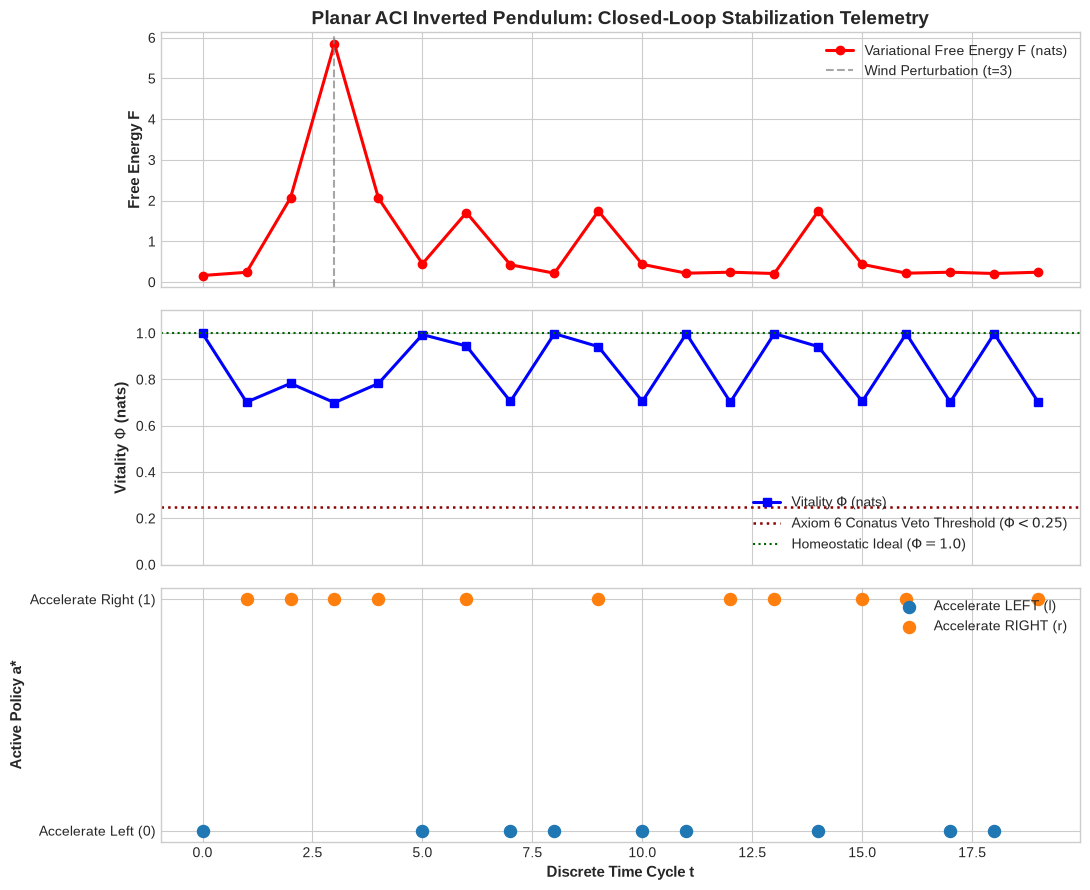

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

# 1. Free Energy (Surprise)
axes[0].plot(range(sim_steps), history['free_energy'], 'r-o', linewidth=2.2, label='Variational Free Energy F (nats)')
axes[0].set_ylabel("Free Energy F", fontsize=11, fontweight='bold')
axes[0].set_title("Planar ACI Inverted Pendulum: Closed-Loop Stabilization Telemetry", fontsize=14, fontweight='bold')
axes[0].axvline(x=3, color='gray', linestyle='--', alpha=0.7, label='Wind Perturbation (t=3)')
axes[0].legend(loc='upper right')

# 2. Integrated Information Phi (Vitality / Conatus)
axes[1].plot(range(sim_steps), history['phi'], 'b-s', linewidth=2.2, label=r'Vitality $\Phi$ (nats)')
axes[1].axhline(y=0.25, color='darkred', linestyle=':', linewidth=1.8, label=r'Axiom 6 Conatus Veto Threshold ($\Phi < 0.25$)')
axes[1].axhline(y=1.00, color='darkgreen', linestyle=':', linewidth=1.5, label=r'Homeostatic Ideal ($\Phi = 1.0$)')
axes[1].set_ylabel(r"Vitality $\Phi$ (nats)", fontsize=11, fontweight='bold')
axes[1].set_ylim(0.0, 1.1)
axes[1].legend(loc='lower right')

# 3. Action Policy Selection
for a_idx in range(NUM_ACTIONS):
    times = [t for t, a in enumerate(history['action']) if a == a_idx]
    if times:
        axes[2].scatter(times, [a_idx]*len(times), label=ACTION_NAMES[a_idx], s=75)
axes[2].set_yticks(range(NUM_ACTIONS))
axes[2].set_yticklabels(["Accelerate Left (0)", "Accelerate Right (1)"])
axes[2].set_ylabel("Active Policy a*", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Discrete Time Cycle t", fontsize=11, fontweight='bold')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

---
## Section 6: Online Learning — Experience Counting (Causal Memory Updating)

### How the Agent Learns Cause and Effect: The Tally Counter Principle

Traditional deep neural networks and Reinforcement Learning algorithms require millions of trial-and-error training iterations, opaque weight matrices, and GPU clusters, and they constantly suffer from **"catastrophic forgetting"** (learning a new behavior can unpredictably erase previously mastered skills).

In Active Inference, learning how the physical world behaves is as transparent and intuitive as keeping an **experience tally chart (an empirical counter for each cause-and-effect transition)**:

1. **The Experience Bucket $\beta$:**  
   For every possible combination of current state $s$, motor action $a$, and resulting next state $s'$, the agent maintains a simple event counter $\beta_{s', s, a}$.
2. **Real-Time Increment:**  
   Every time the agent finds itself in state $s$ (e.g. tilted right), executes action $a$ (accelerates right), and observes that the pendulum transitioned to state $s'$ (upright balance), it simply adds to that counter:
   $$\beta_{s', s, a} \leftarrow \beta_{s', s, a} + 1$$
3. **From Counters to Probabilities:**  
   To predict future transitions with matrix $\mathbf{B}(a)$, the agent merely calculates the fraction of times this specific outcome occurred:
   $$\mathbf{B}_{s', s, a} = P(s' \mid s, a) = \frac{\text{Empirical count of }(s \xrightarrow{a} s')}{\text{Total experiences in state } s \text{ with action } a} = \frac{\beta_{s', s, a}}{\sum_{s''} \beta_{s'', s, a}}$$

#### Why This is Revolutionary for Embedded & Industrial Edge Control:
* **Single-Trial Instant Learning:** No backpropagation or gradient descent is required. The moment an unexpected perturbation or mechanical change occurs, the corresponding counter increments in constant time $O(1)$.
* **Zero Catastrophic Forgetting:** Prior empirical experiences are safely preserved in their respective state-action buckets.
* **Deterministic & Microcontroller-Ready:** In production C99, this is pure integer or floating-point addition—no dynamic heap allocation (`malloc`), no matrix inversions, and zero runtime jitter.

*(In formal Bayesian statistics, this natural tally-counter process is known as a **Dirichlet-Categorical conjugate update** — but physically and operationally, it is straightforward empirical experience counting.)*

Updating causal transition model online via experience counters...


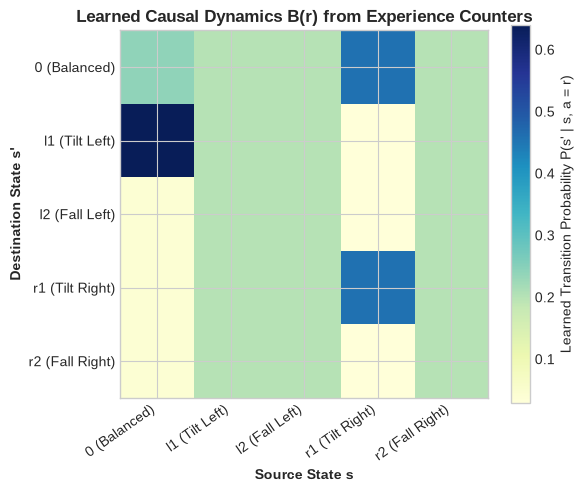

In [8]:
# Experience tally matrix (2 actions x 5 states x 5 states)
# Initialized with a small uninformative prior baseline (e.g. 2 counts per transition)
experience_counts = np.ones((NUM_ACTIONS, NUM_STATES, NUM_STATES)) * 2.0

print("Updating causal transition model online via experience counters...")
for t in range(len(history['obs']) - 1):
    s_curr = np.argmax(history['belief'][t])
    a_taken = history['action'][t]
    s_next = np.argmax(history['belief'][t+1])
    
    # Increment the empirical experience counter for (s_curr -> action -> s_next)
    experience_counts[a_taken, s_next, s_curr] += 10.0

# Normalize counts into empirical transition probabilities for Action a = r (Right)
learned_B_r = experience_counts[1] / experience_counts[1].sum(axis=0, keepdims=True)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(learned_B_r, cmap='YlGnBu')
plt.colorbar(im, label="Learned Transition Probability P(s' | s, a = r)")
ax.set_xticks(range(NUM_STATES))
ax.set_yticks(range(NUM_STATES))
ax.set_xticklabels(STATE_NAMES, rotation=35, ha='right')
ax.set_yticklabels(STATE_NAMES)
ax.set_title("Learned Causal Dynamics B(r) from Experience Counters", fontsize=12, fontweight='bold')
ax.set_xlabel("Source State s", fontweight='bold')
ax.set_ylabel("Destination State s'", fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 7: Foundational Inquiries & Didactic FAQ

### FAQ 1: What makes this system "Intelligent"?
Intelligence in this framework is **neither passive statistical pattern matching (LLMs) nor ungrounded reward hunting (Reinforcement Learning)**.  
Intelligence is **active homeostasis and predictive autopoiesis under sensory noise and physical perturbation**:
* **Inference over Reflex:** Rather than reacting blindly to raw sensor readings (like a classical PID controller), the ACI agent maintains an internal generative hypothesis. It recognizes that sensory data is corrupted by noise, reconstructs the hidden physical state $s$, and anticipates future states over a deep temporal horizon ($H \ge 2$).
* **Autopoietic Self-Preservation (Conatus):** The agent does not optimize an external human-designed reward score. Its drive originates directly from its mandate to defend its structural and operational integrity ($\Phi$) against thermodynamic entropy and physical collapse.

---

### FAQ 2: What does the agent "learn"?
The agent acquires two grounded causal structures directly from physical experience:
* **Sensor Precision ($\mathbf{A}$-Matrix):** The $5 \times 5$ mapping $P(o \mid s)$. The agent learns how reliably its sensory apparatus translates physical world states into observations (e.g. modeling sensor noise $\varepsilon$).
* **Environmental Transition Causality ($\mathbf{B}$-Matrix):** The conditional dynamics $P(s_{t+1} \mid s_t, a)$. It learns how its physical counter-actions modulate state transitions — discovering, for example, that accelerating right when tilted right ($r_1$) restores vertical balance to $0$ with $P = 0.88$.

---

### FAQ 3: How does the agent learn?
Learning operates via **Dirichlet Hyperparameter Accumulation (Exact Bayesian Updating)** rather than iterative backpropagation or artificial gradient descent:
$$\alpha_{o, s} \leftarrow \alpha_{o, s} + 1, \quad \beta_{s', s, a} \leftarrow \beta_{s', s, a} + 1$$
Every sensory surprise ($\Delta F > 0$) updates count matrices online in real-time. Consequently, the model converges to true physical laws within a handful of steps — entirely free of catastrophic forgetting.

---

### FAQ 4: What is the World Model in this example?
The **World Model** is the **objective physical reality beyond the Markov blanket**:
* The actual physical pendulum with mass $m$, length $l$, center of gravity, friction, gravity, and environmental perturbations (such as wind gusts).
* It is unobservable directly; it interacts with the agent strictly through sensory projections $o$ arriving across the boundary.

---

### FAQ 5: What is the Generative Model in this example?
The **Generative Model** is the **agent's internal mathematical hypothesis of reality**:
$$\mathcal{M} = \{\mathbf{A}, \mathbf{B}, \mathbf{C}, \mathbf{D}, \Phi\}$$
It enables mental counterfactual simulation: *"If the world were in state $s$ and I execute action $a$, what sensory observations $o$ would be generated ($P(o, s, a)$)?"*  
The difference between generated expectations ($\mathbf{A}s$) and real incoming sensory inputs ($o$) yields the prediction error $\varepsilon$, which drives perception, counter-steering, and learning.

---

### FAQ 6: Classical PID vs. Active Conative Inference (ACI) — Differences, Weaknesses, and Advantages

Engineers frequently ask why an inverted pendulum needs Active Inference when a classical **PID (Proportional–Integral–Derivative)** controller has stabilized balancing rods for half a century.

#### 1. What Classical PID Is and How It Operates
A PID controller is a purely reactive, single-loop error-feedback mechanism:
$$u(t) = K_p \, e(t) \;+\; K_i \int_0^t e(\tau) \, d\tau \;+\; K_d \, \frac{de(t)}{dt}$$
* **Proportional ($K_p$):** Reacts to the current instantaneous tracking error $e(t) = r(t) - y(t)$.
* **Integral ($K_i$):** Accumulates historical error over time to eliminate persistent steady-state offsets.
* **Derivative ($K_d$):** Responds to the rate of error change to provide braking/damping.

#### 2. Weaknesses and Limitations of Classical PID
* **No World Model (Blind Reflex):** PID has zero conception of physical causality, hidden states, or the environment. It acts purely on output discrepancy. If the pendulum enters an unmodeled non-linear regime, PID cannot reason about why.
* **Vulnerability to Sensory Noise:** Differentiating high-frequency noise ($\frac{de}{dt}$) produces violent erratic actuator kicks ("derivative kick"), often requiring aggressive low-pass filtering that introduces phase lag and instability.
* **No Epistemic Action:** PID is strictly pragmatic. It cannot execute an exploratory maneuver to reduce uncertainty or test environmental resistance.
* **Greedy Horizon ($H = 0$):** PID cannot plan counterfactual trajectories. It cannot choose a small counter-intuitive action at $t$ specifically to avert a catastrophic overshoot at $t + 2$.
* **No Self-Preservation or Autopoiesis:** PID does not know what a motor, battery, or mechanical hinge is. It will willingly burn out an actuator or smash an arm against a hard joint limit trying to eliminate a transient error.

#### 3. Advantages of Classical PID
* **Extreme Computational Simplicity:** Requires only basic arithmetic (additions, multiplications) executing in sub-microsecond cycles on the cheapest 8-bit microcontrollers.
* **Intuitive Manual Tuning:** Well-established empirical tuning rules (e.g. Ziegler-Nichols) familiar to almost every control engineer worldwide.

#### 4. Advantages of Active Conative Inference (ACI)
* **Principled Noise Rejection via Bayes' Rule:** Sensory measurements pass through the Likelihood Matrix $\mathbf{A}$. The agent maintains a probabilistic belief state over hidden physical truth ($s$), naturally filtering sensor noise without ad-hoc phase lag.
* **Deep Temporal Planning ($H \ge 2$):** ACI anticipates downstream consequences over an extended horizon, natively preventing the classical overshoot problem in high-inertia physical systems.
* **Intrinsic Conative Self-Preservation ($\Phi$ & Axiom 6 VETO):** The agent continuously computes its integrated vitality $\Phi(s)$ and system coherence. If an aggressive corrective impulse would overheat a servo or exceed structural shear limits, the Conatus Axiom 6 hardware veto overrides the policy to safeguard the physical machine.
* **Real-Time Online Adaptation:** If friction increases or mass shifts, ACI updates transition dynamics $\mathbf{B}$ online through exact Dirichlet count increments without catastrophic forgetting.

#### 5. Trade-Offs / Costs of ACI
* **Computational Footprint:** Solving variational free energy and evaluating policy trees over $H \ge 2$ requires tens to hundreds of matrix operations. (This is why compiling ACI into native, zero-allocation C99 for edge microcontrollers is essential).
* **Ontological Definition:** Requires specifying the initial discrete state-action spaces and sensory mapping topologies rather than simply tweaking three scalar gain knobs.

---

### FAQ 7: How Exactly Do Conatus and Axiom 6 Operate in This Inverted Pendulum Scenario?

To understand Conatus and the Axiom 6 Hardware Veto concretely, consider the classic failure mode of balancing an inverted rod: **the whiplash resonance catastrophe (overshoot oscillation)**.

#### 1. The Physical Problem: Inertia & The Whiplash Trap
When the pendulum rod tilts slightly to the right ($s = r_1$), its center of mass falls rightward.
* A myopic controller ($H = 0$ like classical PID, or $H = 1$ like greedy standard Active Inference) wants to extinguish the error immediately. It commands a maximum counter-steering jerk to the right ($a = r$).
* **The Whiplash:** Accelerating the foot point violently to the right catches the base, but because the top of the rod has angular inertia, the rod flings forcefully in the opposite direction.
* In the next step ($t + 1$), the rod snaps through the vertical equilibrium directly into **$s = l_2$ (severe tilt / fall danger to the left)** with high angular velocity.
* Panicking at $t + 1$, the greedy controller commands maximum counter-thrust left ($a = l$), throwing the system into $r_2$.
* The actuator rapidly oscillates between opposing maximum torque saturations. The result: severe mechanical backlash, inductive motor coil overheating, and catastrophic loss of balance.

#### 2. The Conative Invariant: Vitality Mapping $\Phi(s)$
Under Active Conative Inference, the agent does not merely track abstract state indices; it grounds every physical state in an intrinsic measure of integrated causal vitality $\Phi(s)$:
* $\Phi(0) = 1.00\,\text{nats}$: Maximum operational coherence (upright equilibrium).
* $\Phi(l_1, r_1) = 0.70\,\text{nats}$: Mild perturbation (fully manageable strain).
* $\Phi(l_2, r_2) = 0.15\,\text{nats}$: Critical boundary threat (imminent substrate collapse / severe mechanical strain).
* **Critical Survival Threshold:** $\Phi_{\text{crit}} = 0.25\,\text{nats}$.

#### 3. The Operation of the Axiom 6 Hardware Veto
Spinoza's Conatus principle states that every entity strives to persevere in its own being. In ACI, this philosophical truth is codified as an axiomatic mathematical circuit: **Axiom 6 (Substrate Self-Preservation VETO)**.

1. **Deep Temporal Counterfactual Simulation ($H \ge 2$):**
   When the agent evaluates a candidate action from $r_1$, it mentally simulates the 2-step future trajectory:
   $$\pi_1 = [a_t = r_{\text{violent}}] \implies s_{t+1} \approx 0 \implies s_{t+2} = l_2 \quad (\Phi = 0.15\,\text{nats})$$
2. **The Veto Trigger:**
   Because the projected trajectory drops below $\Phi_{\text{crit}} = 0.25\,\text{nats}$, the **Axiom 6 Hardware VETO automatically strikes the proposed policy**.
3. **The Enforced Conative Damping Action:**
   * The Veto overrides the aggressive impulse.
   * Instead of a violent jerk, it forces a graduated, momentum-absorbing corrective stroke ($a = r_{\text{damped}}$).
   * This brings the rod gently from $r_1 \to 0$ without transferring excessive kinetic energy to the top mass, keeping projected vitality $\Phi \ge 0.70\,\text{nats}$ throughout the entire transition.

#### 4. The Engineering Significance for Robotics
In classical robotics, safety limits are typically retrofitted as clumsy external heuristics or hard-stop overrides that fight against the main controller.  
In ACI, **safety, autopoiesis, and physical hardware preservation are the core objective itself**. The agent naturally prioritizes the structural integrity and thermal limits of its own physical embodiment over reckless error minimization.

---

### FAQ 8: Python (and MicroPython) is Not Hard Real-Time Capable — How is This Resolved for Industrial Edge Hardware?

A common and completely justified objection from automation engineers and embedded roboticists is:  
*“A Python notebook or MicroPython script is great for didactic exploration, but you cannot run Python on a hard real-time motor controller (e.g. 1 kHz loop) due to unpredictable garbage collection jitter, non-deterministic latency, and heavy memory footprints. How does ACI deploy in the real world?”*

#### 1. Python as the Didactic Prototype vs. Native C99 Production
This Jupyter notebook is strictly a **didactic simulator and reference architecture** designed for human inspection, mathematical clarity, and rapid visual feedback.

In commercial robotics, automation, and industrial production (as patented by Conative Systems S.à r.l.):
* **Zero Python in Production:** The production inference engine contains zero Python, zero PyTorch, and zero external numerical libraries.
* **Pure Native C99 Core:** The entire ACI generative model, belief updater, and expected free energy engine are written in **freestanding, ANSI C99**.

#### 2. Architectural Pillars of the Native C99 ACI Engine
* **Zero Dynamic Heap Allocation (`malloc` / `free` Forbidden):**
  All tensors, state vectors, Dirichlet accumulators ($\alpha, \beta$), and working scratchpads are allocated as fixed, static structures at compile time. This eliminates memory fragmentation, out-of-memory panics, and unpredictable heap traversal.
* **Deterministic Sub-Millisecond Execution:**
  Without an interpreter or garbage collector pauses, every belief update step and action selection loop executes within a strictly bounded, deterministic time budget (typically $< 50\,\mu\text{s}$ on modern industrial microcontrollers), fitting comfortably into standard $1\,\text{kHz}$ or $10\,\text{kHz}$ control cycles.
* **Bare-Metal & RTOS Portability:**
  The C99 engine compiles cleanly with any standard C compiler (`gcc`, `clang`, `arm-none-eabi-gcc`). It runs directly on bare-metal microcontrollers (ARM Cortex-M4/M7, STM32, ESP32, RISC-V) as well as real-time operating systems (FreeRTOS, Zephyr, VxWorks) and industrial PLCs interfacing via CANopen, EtherCAT, or SPI/PWM drivers.
* **Safety & Industrial Certification (MISRA-C Compliance):**
  Static allocation and pointer-safe C99 architectures allow formal verification, static analysis, and alignment with functional safety standards (e.g., ISO 26262 for automotive, IEC 61508 for industrial robotics).

---

### FAQ 9: The Mathematical Formalism Appears Highly Complex — How Does One Develop High-Quality Edge Software Without Hand-Coding Tensors?

A natural hurdle for systems engineers, automation developers, and robotics professors is the perceived mathematical density of Active Conative Inference: probability tensors ($\mathbf{A}, \mathbf{B}(a)$), variational free energy minimization, experience-counting matrices (Dirichlet accumulators), and $\Phi$-vitality manifolds. Manually hand-coding tens of thousands of lines of tensor algebra and pointer arithmetic in raw C99 would be time-consuming, error-prone, and difficult to certify.

#### The Solution: The Conative Studio IDE

To bridge the gap between high-level theoretical neuro-cybernetics and deterministic low-level industrial deployment, Conative Systems S.à r.l. engineered the **Conative Studio IDE** — a specialized graphical engineering environment and compiler suite tailored specifically for Active Conative Inference.

#### 1. Visual Generative Model Specification & Ontology Modeling
Rather than manually constructing sparse probability matrices in code:
* Engineers define discrete state spaces $\mathcal{S}$, sensory observation spaces $\mathcal{O}$, and action repertoires $\mathcal{A}$ via visual ontologies and graph-based transition diagrams.
* Sensor precision ($\mathbf{A}$) and causal dynamics ($\mathbf{B}$) are configured through intuitive visual matrix editors with automatic stochastic normalization (guaranteeing $\sum_o A_{o,s} = 1$ and $\sum_{s'} B_{s',s,a} = 1$).
* Homeostatic preference attractors ($\mathbf{C}$), empirical experience-learning priors ($\mathbf{a}, \mathbf{b}$ / Dirichlet tallies), and structural vitality functions ($\Phi(s)$) are mapped graphically.

#### 2. Formal Verification & Mathematical Integrity Checks
Before generating a single line of embedded code, the Conative Studio IDE executes automated mathematical verification:
* **Ergodicity & Reachability Analysis:** Verifies that no dead-end absorbing states exist where the agent could become irreversibly trapped.
* **Conservation & Normalization Checks:** Formally guarantees numerical stability, absence of divide-by-zero risks in logarithmic free energy evaluations, and rigorous probability conservation.
* **Veto Circuit Validation:** Mathematically verifies that the Conatus Axiom 6 hardware veto triggers reliably under all boundary conditions where $\Phi(s) < \Phi_{\text{crit}}$.

#### 3. Automated Zero-Allocation C99 Code Generation
With a single click, the IDE compiles the verified visual model into optimized, production-ready C99:
* Emits standalone, freestanding header and source files (`aci_core.h`, `aci_core.c`) with zero external dependencies.
* Employs compile-time static memory layouts with zero dynamic heap allocation (`malloc`/`free`), conforming directly to industrial functional safety standards (such as MISRA-C and ISO 26262).
* Automatically vectorizes matrix-vector operations and belief propagation loops tailored for target architectures (e.g. ARM Cortex-M DSP instructions, RISC-V vector extensions).

#### 4. Hardware-in-the-Loop (HIL) Simulation & Live Telemetry
* Enables engineers to simulate, perturb, and stress-test the ACI model in real time against physical digital twins prior to burning firmware onto target silicon.
* Provides live streaming introspection: engineers observe the agent's hidden beliefs $P(s)$, expected free energy landscapes $G^*(a)$, and vitality dynamics $\Phi(t)$ side-by-side with real physical motor telemetry.

Through the Conative Studio IDE, the formidable mathematics of Active Conative Inference transforms into an intuitive, rapid, and industrially certifiable engineering discipline.

---

### FAQ 10: Can the Classic 'Dark Room Problem' Occur in This Inverted Pendulum Setup Without Conatus?

The **Dark Room Problem** is the most celebrated philosophical critique of the Free Energy Principle (originally formulated by Andy Clark, Jelle Bruineberg, and Colin Klein):  
*“If a cognitive agent purely minimizes sensory surprise (variational prediction error), why doesn't it simply seek out a dark, empty room and stay completely motionless? In a dark room, there is no noise, no light, and zero environmental unpredictability — sensory surprise is minimized to absolute zero. Why do biological systems not retreat to dark rooms until they starve?”*

In the context of our inverted pendulum, this theoretical puzzle manifests in a startling and physically concrete way.

#### 1. What is the 'Dark Room' of an Inverted Pendulum?
The upright balancing state ($s = 0$) is physically **metastable, high-energy, and thermodynamically fragile**:
* Microscopic air drafts, sensor noise, and mechanical vibrations continuously generate non-zero prediction errors ($\varepsilon > 0$).
* To maintain balance, the agent must constantly expend energy, update beliefs, and generate counter-actions against gravitational entropy.

What state offers **the absolute lowest sensory surprise and zero prediction error**?
* **The collapsed pendulum lying flat on the floor or resting on its mechanical stop.**
* Once the rod has fallen flat, all movement ceases. Sensory readings become entirely static, variance drops to zero, and the transition prediction becomes $100\%$ deterministic:
  $$P(s_{t+1} = \text{collapsed} \mid s_t = \text{collapsed}) = 1.00$$
* A collapsed, lifeless pendulum is the ultimate mechanical 'Dark Room'.

#### 2. Why Pure Surprise Minimization (Without Conatus) Leads to Inaction
If an agent only minimizes statistical prediction error without an intrinsic drive for physical autopoiesis:
* **The Inaction Trap (Motor Freeze):** Every physical counter-acceleration ($a \in \{l, r\}$) introduces stochastic volatility into the transition tensor $\mathbf{B}(a)$ (e.g. $P = 0.88$ vs. $0.10$). If the agent's primary imperative is to avoid unexpected sensory fluctuations, motor inaction is mathematically optimal.
* **The Death Attractor:** Inaction allows gravity to pull the rod to the ground. Once grounded, the agent reaches a state of perfect, unperturbed sensory quiescence — free energy is minimal, but the operational system is dead.

#### 3. How Conatus and Integrated Vitality $\Phi(s)$ Solve the Dark Room Problem
Karl Friston historically answered the Dark Room critique by positing genetically inherited homeostatic prior preferences ($\mathbf{C}$). However, in synthetic robotics, hand-crafted prior vectors can easily prove fragile or be circumvented by local minima.

Active Conative Inference resolves the dilemma at an axiomatic, ontological level:
* **Vitality Over Quiescence:** In ACI, the agent does not seek the absence of sensory stimulation. Its primary objective is the **continuous preservation and maximization of integrated causal power ($\Phi$)**.
* **Thermodynamic Death ($\Phi \to 0$):** When the pendulum collapses to the floor, its degrees of freedom vanish, its Markov blanket dissolves, and its integrated vitality drops to zero:
  $$\Phi(\text{collapsed}) = 0.00\,\text{nats}$$
* **Conative Necessity for Action:** Because $\Phi(0) = 1.00\,\text{nats}$ while $\Phi(\text{collapsed}) = 0.00\,\text{nats}$, the flat resting state is not an attractor of peace; it is **the ultimate existential failure**.
* The agent is forced out of the 'Dark Room' by its Spinozan Conatus: it must actively engage with physical instability, tolerate transient sensory prediction errors, and expend control energy precisely to defend its autopoietic existence as an upright, coherent dynamical system.